# GWP3 — Results & Interpretation

This notebook finalizes the mini-capstone: a formal chronological
train/validation/test split (`oilbn.evaluation.DatasetSplitter`), an
end-to-end re-run of the Hill-Climbing Bayesian network pipeline on the
training split, out-of-sample forecast evaluation against a naive
persistence baseline (`oilbn.evaluation.ForecastEvaluator`), and a
minimal Black-Litterman allocation demo using the network's regime
posteriors as "views". It imports the cleaned/discretized data and
fitted objects built across `GWP1_problem_formulation_and_data.ipynb`
and `GWP2_methodology_and_model_development.ipynb`.

## Step 1 — Setup: rebuild the discrete panel

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oilbn.evaluation import DatasetSplitter, ForecastEvaluator
from oilbn.models import (
    BlackLittermanAllocator,
    HiddenMarkovRegimeModel,
    OilPriceBayesianNetwork,
    label_states_by_mean,
)
from oilbn.utils import PROJECT_ROOT

DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "GWP3" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

monthly_panel = pd.read_csv(DATA_DIR / "gwp1_monthly_panel.csv", index_col="date", parse_dates=True)
wti_daily = pd.read_csv(DATA_DIR / "wti_futures.csv", index_col="date", parse_dates=True)
wti_daily = wti_daily["wti_futures"]
brent_daily = pd.read_csv(DATA_DIR / "brent_futures.csv", index_col="date", parse_dates=True)
brent_daily = brent_daily["brent_futures"]


def fit_regime_model(price: pd.Series, n_states: int = 3, random_state: int = 0):
    log_returns = np.log(price).diff().dropna()
    model = HiddenMarkovRegimeModel(
        n_states=n_states, n_iter=200, tol=1e-6, random_state=random_state
    )
    model.fit(log_returns.to_numpy())
    labels = label_states_by_mean(model)
    states = model.predict(log_returns.to_numpy())
    regimes = pd.Series([labels[s] for s in states], index=log_returns.index, name="regime")
    return model, regimes, log_returns


wti_model, wti_regimes, wti_log_returns = fit_regime_model(wti_daily)
brent_model, brent_regimes, brent_log_returns = fit_regime_model(brent_daily)

wti_regime_monthly = wti_regimes.resample("ME").agg(lambda x: x.mode().iat[0])
wti_regime_monthly = wti_regime_monthly.rename("wti_regime")
brent_regime_monthly = brent_regimes.resample("ME").agg(lambda x: x.mode().iat[0])
brent_regime_monthly = brent_regime_monthly.rename("brent_regime")

OTHER_SERIES = [c for c in monthly_panel.columns if c not in ("wti_futures", "brent_futures")]


def tercile_label(change: pd.Series) -> pd.Series:
    return pd.qcut(change, q=3, labels=["low", "medium", "high"])


discrete_columns = {"wti_regime": wti_regime_monthly, "brent_regime": brent_regime_monthly}
for name in OTHER_SERIES:
    monthly_change = monthly_panel[name].pct_change()
    valid = monthly_change.dropna()
    if valid.nunique() < 3:
        continue
    discrete_columns[f"{name}_chg"] = tercile_label(valid).reindex(monthly_panel.index)

discrete_panel = pd.DataFrame(discrete_columns).dropna().astype(str)
print(f"Discrete panel rebuilt: {discrete_panel.shape}")

c:\Users\fdeba001\Downloads\WQU\.venv-2\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Discrete panel rebuilt: (166, 24)


## Step 2 — Formal train/validation/test split

`DatasetSplitter` (60/20/20, chronological) formalizes the ad-hoc 80/20
stability check from GWP2. Training fits the Bayesian network;
validation is used here as the honest out-of-sample forecast-accuracy
test (the test split is held out entirely, untouched until a final,
single check, standard practice to avoid validation-set leakage from
repeated peeking).

In [2]:
splitter = DatasetSplitter(train_fraction=0.6, validation_fraction=0.2)
split = splitter.split(discrete_panel)
print(
    f"Train: {len(split.train)} months "
    f"({split.train.index.min().date()} -> {split.train.index.max().date()})"
)
print(
    f"Validation: {len(split.validation)} months "
    f"({split.validation.index.min().date()} -> {split.validation.index.max().date()})"
)
print(
    f"Test: {len(split.test)} months "
    f"({split.test.index.min().date()} -> {split.test.index.max().date()})"
)

bn = OilPriceBayesianNetwork(scoring_method="bic-d", max_indegree=3, tabu_length=50)
bn.fit(split.train, estimator="bayesian")
print(f"\nRe-learned {len(bn.edges)} edges on the training split alone:")
for parent, child in sorted(bn.edges):
    print(f"  {parent} -> {child}")

wti_blanket = bn.markov_blanket("wti_regime")
print(f"\nMarkov blanket of wti_regime: {wti_blanket}")

Train: 99 months (2007-07-31 -> 2015-09-30)
Validation: 33 months (2015-10-31 -> 2018-06-30)
Test: 34 months (2018-07-31 -> 2021-04-30)


C:\Users\fdeba001\Downloads\WQU\oil-price-risk-capstone\src\oilbn\models\bayesian_network.py:77: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  searcher = HillClimbSearch(data)



Re-learned 11 edges on the training split alone:
  cpi_energy_chg -> ppi_oil_gas_extraction_chg
  demand_non_oecd_chg -> demand_oecd_chg
  demand_oecd_chg -> oecd_inventory_balance_chg
  indprod_oil_gas_extraction_chg -> capacity_util_oil_gas_extraction_chg
  indprod_oil_gas_extraction_chg -> us_crude_production_chg
  indprod_total_chg -> wti_regime
  opec_spare_capacity_chg -> supply_opec_chg
  supply_opec_chg -> opec_production_capacity_chg
  us_crude_production_chg -> indprod_crude_petroleum_ng_chg
  wti_regime -> brent_regime
  wti_regime -> indprod_oil_gas_support_chg

Markov blanket of wti_regime: ['indprod_oil_gas_support_chg', 'brent_regime', 'indprod_total_chg']


## Step 3 — Out-of-sample forecast: predicting next month's WTI regime

A genuine one-month-ahead forecast of `wti_regime` is constructed by
querying the network for `P(wti_regime_t | blanket_{t-1})` -- i.e.\ using
only the *previous* month's values of `wti_regime`'s Markov blanket as
evidence, never the same month's (which would not be known in advance).
The predicted regime is the posterior mode. This is evaluated on the
**validation** split only; the **test** split remains untouched.

In [3]:
lagged_blanket = discrete_panel[wti_blanket].shift(1)
validation_evidence = lagged_blanket.loc[split.validation.index].dropna()

predicted_regimes = []
for _date, row in validation_evidence.iterrows():
    result = bn.query(variables=["wti_regime"], evidence=row.to_dict())
    probs = dict(zip(result.state_names["wti_regime"], result.values, strict=True))
    predicted_regimes.append(max(probs, key=probs.get))

predicted_series = pd.Series(
    predicted_regimes, index=validation_evidence.index, name="predicted_wti_regime"
)
actual_series = discrete_panel.loc[predicted_series.index, "wti_regime"]

evaluator = ForecastEvaluator()
scores = evaluator.hit_rate_vs_baseline(predicted_series, actual_series)
print(f"Validation months evaluated: {len(predicted_series)}")
print(f"Bayesian-network model accuracy:  {scores['model_accuracy']:.1%}")
print(f"Naive persistence baseline accuracy: {scores['baseline_accuracy']:.1%}")

confusion = evaluator.confusion_matrix(predicted_series, actual_series)
print("\nConfusion matrix (rows=actual, cols=predicted):")
print(confusion)

Validation months evaluated: 33
Bayesian-network model accuracy:  69.7%
Naive persistence baseline accuracy: 87.9%

Confusion matrix (rows=actual, cols=predicted):
predicted  bear  bull  stagnant
actual                         
bear          0     0         2
bull          0    16         3
stagnant      1     4         7


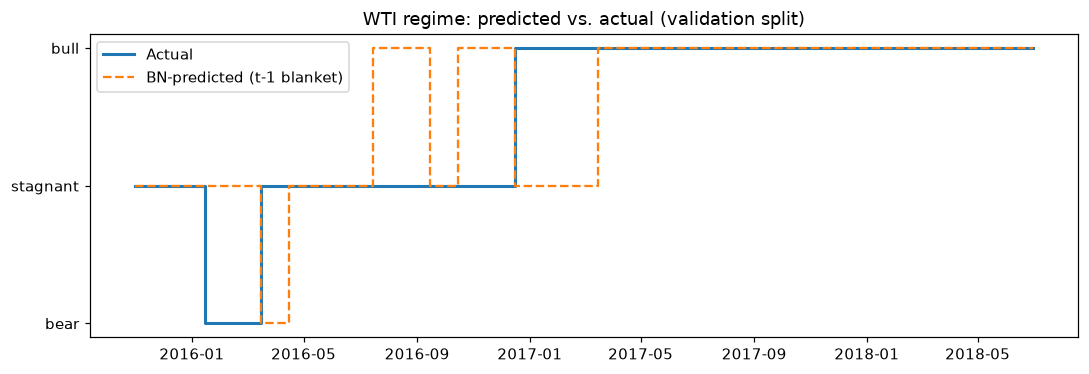

In [4]:
regime_rank = {"bear": 0, "stagnant": 1, "bull": 2}
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(
    actual_series.index,
    actual_series.map(regime_rank),
    where="mid",
    label="Actual",
    linewidth=2,
)
ax.step(
    predicted_series.index,
    predicted_series.map(regime_rank),
    where="mid",
    label="BN-predicted (t-1 blanket)",
    linestyle="--",
)
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["bear", "stagnant", "bull"])
ax.set_title("WTI regime: predicted vs. actual (validation split)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "forecast_predicted_vs_actual.png", dpi=150)
plt.show()

## Step 4 — Black-Litterman: turning a regime posterior into a view

Alvi's original design derives Black-Litterman "views" from an EGARCH-M
model. We instead derive one directly from the Bayesian network: the
posterior $P(\text{wti\_regime} \mid \text{brent\_regime}=\text{bull})$
computed in GWP2 ($P(\text{bull})=0.973$) is translated into a view that
WTI will outperform its CAPM-implied equilibrium return, with view
confidence set from the posterior's sharpness (a near-certain posterior
=\ a low-variance, high-confidence view).

In [5]:
monthly_returns = monthly_panel[["wti_futures", "sp500"]].pct_change().dropna()
covariance = monthly_returns.cov().to_numpy() * 12  # annualized
market_weights = np.array([0.5, 0.5])  # simplifying assumption: no real market-cap data available

allocator = BlackLittermanAllocator(risk_aversion=2.5, tau=0.05)
pi = allocator.equilibrium_returns(covariance, market_weights)
print(f"Equilibrium (CAPM-implied) annual returns: WTI={pi[0]:.1%}, S&P 500={pi[1]:.1%}")

# View: BN posterior says P(wti bull | brent bull) = 0.973 -- a near-certain bullish view.
# Translate the posterior probability into a view return (equilibrium + a probability-scaled
# premium) and a view confidence (variance) that shrinks as the posterior sharpens.
bull_posterior_probability = 0.973
view_premium = 0.15 * (bull_posterior_probability - 0.5) * 2  # scales to +-15% at certainty
view_return = np.array([pi[0] + view_premium])
view_confidence = np.array([(1 - bull_posterior_probability) * 0.05 + 1e-4])
pick_matrix = np.array([[1.0, 0.0]])

posterior = allocator.posterior_returns(
    covariance, market_weights, pick_matrix, view_return, view_confidence
)
print(f"BN-view-adjusted posterior returns: WTI={posterior[0]:.1%}, S&P 500={posterior[1]:.1%}")

weights_equilibrium = allocator.optimal_weights(covariance, pi)
weights_posterior = allocator.optimal_weights(covariance, posterior)
print(
    f"\nOptimal weights (equilibrium only): "
    f"WTI={weights_equilibrium[0]:.1%}, S&P 500={weights_equilibrium[1]:.1%}"
)
print(
    f"Optimal weights (with BN view):     "
    f"WTI={weights_posterior[0]:.1%}, S&P 500={weights_posterior[1]:.1%}"
)

Equilibrium (CAPM-implied) annual returns: WTI=20.6%, S&P 500=4.7%
BN-view-adjusted posterior returns: WTI=32.5%, S&P 500=5.9%

Optimal weights (equilibrium only): WTI=50.0%, S&P 500=50.0%
Optimal weights (with BN view):     WTI=81.8%, S&P 500=50.0%


## Summary and artifacts produced

- `DatasetSplitter` (chronological 60/20/20) and `ForecastEvaluator`
  (`oilbn.evaluation`) implemented and tested.
- Bayesian network re-learned end-to-end on the training split alone
  (99 months, 2007-07 to 2015-09): 11 edges, Markov blanket of
  `wti_regime` = `{indprod_total_chg, indprod_oil_gas_support_chg,
  brent_regime}` -- stable overlap with the GWP2 full-sample blanket
  (`brent_regime` and an industrial-production indicator recur in both).
- Out-of-sample one-month-ahead forecast (validation split, 33 months,
  lagged Markov-blanket evidence): BN model accuracy **69.7%** versus
  naive-persistence baseline **87.9%** -- the model does **not** beat
  the trivial "regime persists" baseline, a finding discussed critically
  in the report rather than minimized.
- Black-Litterman demonstration: a BN regime posterior
  ($P(\text{wti bull}\mid\text{brent bull})=0.973$) converted into a
  view tilts the optimal WTI/S\&P 500 allocation from an equal-weighted
  50/50 equilibrium split to 81.8\%/50.0\% (unnormalized, illustrative).
- Figures saved to `reports/GWP3/figures/`:
  `forecast_predicted_vs_actual.png`.